# Hotel Booking Cancellation — Random Forest


- Target: `is_canceled`
- Split: `StratifiedGroupKFold(n_splits=5)`의 첫 번째 fold를 test로 사용
- Train/test 그룹 중복 방지
- 트리 모델 전처리: 수치형 median 대체, 범주형 Unknown 대체 + OneHotEncoder(`min_frequency=20`)
- Random Forest: 50 trees, max_depth=18, min_samples_leaf=2

원본 CSV를 이 노트북과 같은 폴더에 두고 실행하세요.

In [11]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, average_precision_score)
import joblib

RANDOM_STATE = 0
TARGET = "is_canceled"
RAW_PATH = Path("hotel_bookings (RAW).csv")
#assert RAW_PATH.exists(), "원본 CSV 파일을 노트북과 같은 폴더에 넣어 주세요."

LEAK_COLS = [
    "reservation_status", "reservation_status_date", "assigned_room_type",
    "booking_changes", "required_car_parking_spaces"
]
ID_COLS = ["source_row_id", "group_id", "split"]

CAT_COLS = [
    "hotel", "arrival_date_month", "meal", "country", "market_segment",
    "distribution_channel", "reserved_room_type", "deposit_type",
    "agent", "customer_type"
]
NUM_COLS = [
    "lead_time", "arrival_date_year", "arrival_date_week_number",
    "arrival_date_day_of_month", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "is_repeated_guest",
    "previous_cancellations", "previous_bookings_not_canceled",
    "days_in_waiting_list", "adr", "total_of_special_requests",
    "has_company", "total_guests", "total_nights"
]

## 1. 원본 데이터 및 공통 전처리

In [13]:
# CSV 파일 경로 지정
RAW_PATH = (
    r"C:/Users/playdata2/work/팀프로젝트2/모델링 프로젝트/hotel_bookings (RAW).csv"
)

df = pd.read_csv("C:/Users/playdata2/work/팀프로젝트2/모델링 프로젝트/hotel_bookings (RAW).csv")
df.insert(0, "source_row_id", df.index)

# 결측치 처리
df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["has_company"] = df["company"].notna().astype(int)
df = df.drop(columns=["company"])
df["agent"] = df["agent"].apply(
    lambda v: "Unknown" if pd.isna(v) else str(int(v))
)

# 예약 확정 직후 알 수 없는 누수 컬럼 제거
df = df.drop(columns=LEAK_COLS)

# 이상 행 제거: 투숙객 0명, 음수 ADR, ADR 5000 이상
guests = df["adults"] + df["children"] + df["babies"]
df = df[(guests > 0) & (df["adr"] >= 0) & (df["adr"] < 5000)].copy()

# 파생변수
df["total_guests"] = (
    df["adults"] + df["children"] + df["babies"]
).astype(int)
df["total_nights"] = (
    df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
)

# 중복 행은 유지하고 동일 입력 행을 group_id로 묶음
feature_cols = [c for c in df.columns if c not in ["source_row_id", TARGET]]
row_hash = pd.util.hash_pandas_object(df[feature_cols], index=False)
df["group_id"] = pd.factorize(row_hash)[0]
df = df.reset_index(drop=True)

print("전처리 후 데이터:", df.shape)
print("취소율:", round(df[TARGET].mean(), 4))
print("남은 결측치:", int(df.isna().sum().sum()))

전처리 후 데이터: (119208, 31)
취소율: 0.3708
남은 결측치: 0


## 2. 그룹 기반 Train/Test 분할

In [14]:
sgkf = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
_, test_idx = next(sgkf.split(df, df[TARGET], groups=df["group_id"]))

df["split"] = "train"
df.loc[test_idx, "split"] = "test"

train = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

assert set(train["group_id"]).isdisjoint(set(test["group_id"]))

FEATURES = CAT_COLS + NUM_COLS
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print("Train:", X_train.shape, "| 취소율:", round(y_train.mean(), 4))
print("Test :", X_test.shape, "| 취소율:", round(y_test.mean(), 4))
print("Train/Test 그룹 중복:", len(set(train.group_id) & set(test.group_id)))

Train: (95367, 28) | 취소율: 0.3708
Test : (23841, 28) | 취소율: 0.3707
Train/Test 그룹 중복: 0


## 3. 기본 모델 및 하이퍼파라미터 고도화

기본 Random Forest를 기준 모델로 학습한 뒤, **학습 데이터 안에서만** 그룹 기반 교차검증을 수행해 하이퍼파라미터를 탐색합니다. 테스트 데이터는 최종 평가 전까지 튜닝에 사용하지 않습니다.

In [17]:
# 전처리 Pipeline 구성
# 수치형: 중앙값 대체
numeric_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# 범주형: Unknown 대체 후 원-핫 인코딩
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20
    ))
])

tree_preprocessor = ColumnTransformer([
    ("num", numeric_tree, NUM_COLS),
    ("cat", categorical_pipe, CAT_COLS)
])

# 비교 기준이 될 기존 설정의 기본 모델
baseline_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=50,
        max_depth=18,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

baseline_model.fit(X_train, y_train)
print("기본 Random Forest 학습 완료")

# 그룹이 train/test에 나뉘지 않도록 그룹 기반 교차검증 사용
tuning_cv = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
cv_splits = list(
    tuning_cv.split(X_train, y_train, groups=train["group_id"])
)

# 탐색 범위: 트리 수, 깊이, 분할/리프 최소 샘플 수, 특성 수, 클래스 가중치
param_distributions = {
    "model__max_depth": [10],
    "model__min_samples_leaf": [1, 2]
    
}

search = RandomizedSearchCV(
    estimator=Pipeline([
        ("preprocessor", tree_preprocessor),
        ("model", RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=1
        ))
    ]),
    param_distributions=param_distributions,
    n_iter=20,
    scoring="roc_auc",
    cv=cv_splits,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    refit=True,
    return_train_score=True
)

search.fit(X_train, y_train)
rf_model = search.best_estimator_

print("\n최적 하이퍼파라미터")
print(search.best_params_)
print(f"교차검증 최고 ROC-AUC: {search.best_score_:.4f}")
print("고도화 모델 학습 완료")

기본 Random Forest 학습 완료


c:\Users\playdata2\anaconda3\envs\ml\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 2 is smaller than n_iter=20. Running 2 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 2 candidates, totalling 10 fits

최적 하이퍼파라미터
{'model__min_samples_leaf': 1, 'model__max_depth': 10}
교차검증 최고 ROC-AUC: 0.9064
고도화 모델 학습 완료


## 4. 테스트 데이터 최종 평가 및 모델 비교

하이퍼파라미터 선택에는 학습 데이터의 그룹 기반 교차검증만 사용했습니다. 아래 테스트 지표는 최종 일반화 성능 확인용입니다.

In [19]:
def evaluate_classifier(model, X, y, model_name):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1-score": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, proba),
        "PR-AUC": average_precision_score(y, proba)
    }

comparison = pd.DataFrame([
    evaluate_classifier(baseline_model, X_test, y_test, "Baseline RF"),
    evaluate_classifier(rf_model, X_test, y_test, "Tuned RF")
]).set_index("Model")

display(comparison.round(4))

# 이후 분석·저장 셀에서는 고도화 모델을 사용
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

results = comparison.loc["Tuned RF"].drop("Model", errors="ignore").to_dict()
pd.Series(results, name="score").to_frame().round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Model,,,,,,
Baseline RF,0.8349,0.8811,0.6414,0.7424,0.9263,0.8959
Tuned RF,0.7892,0.9609,0.4498,0.6128,0.9095,0.8796


,score
Accuracy,0.7892
Precision,0.9609
Recall,0.4498
F1-score,0.6128
ROC-AUC,0.9095
PR-AUC,0.8796


In [21]:
print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, digits=4))

Confusion Matrix
[[14840   162]
 [ 4863  3976]]

              precision    recall  f1-score   support

           0     0.7532    0.9892    0.8552     15002
           1     0.9609    0.4498    0.6128      8839

    accuracy                         0.7892     23841
   macro avg     0.8570    0.7195    0.7340     23841
weighted avg     0.8302    0.7892    0.7653     23841



## 5. 하이퍼파라미터 탐색 결과

교차검증에서 선택된 조합과 상위 후보를 확인합니다. `mean_test_score`는 학습 데이터 내 그룹 기반 교차검증 ROC-AUC입니다.

In [22]:
tuning_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(tuning_results[[
    "rank_test_score", "mean_test_score", "std_test_score", "mean_train_score", "params"
]].head(10).round(4))

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
0,1,0.9064,0.0067,0.9201,"{'model__min_samples_leaf': 1, 'model__max_dep..."
1,2,0.9062,0.0061,0.9180,"{'model__min_samples_leaf': 2, 'model__max_dep..."


## 6. 특성 중요도

In [23]:
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
importances = rf_model.named_steps["model"].feature_importances_

feature_importance = (
    pd.DataFrame({"feature": feature_names, "importance": importances})
      .sort_values("importance", ascending=False)
)
display(feature_importance.head(5))

,feature,importance
131,cat__deposit_type_No Deposit,0.126850
132,cat__deposit_type_Non Refund,0.121755
89,cat__country_PRT,0.106511
0,num__lead_time,0.079764
14,num__total_of_special_requests,0.074416


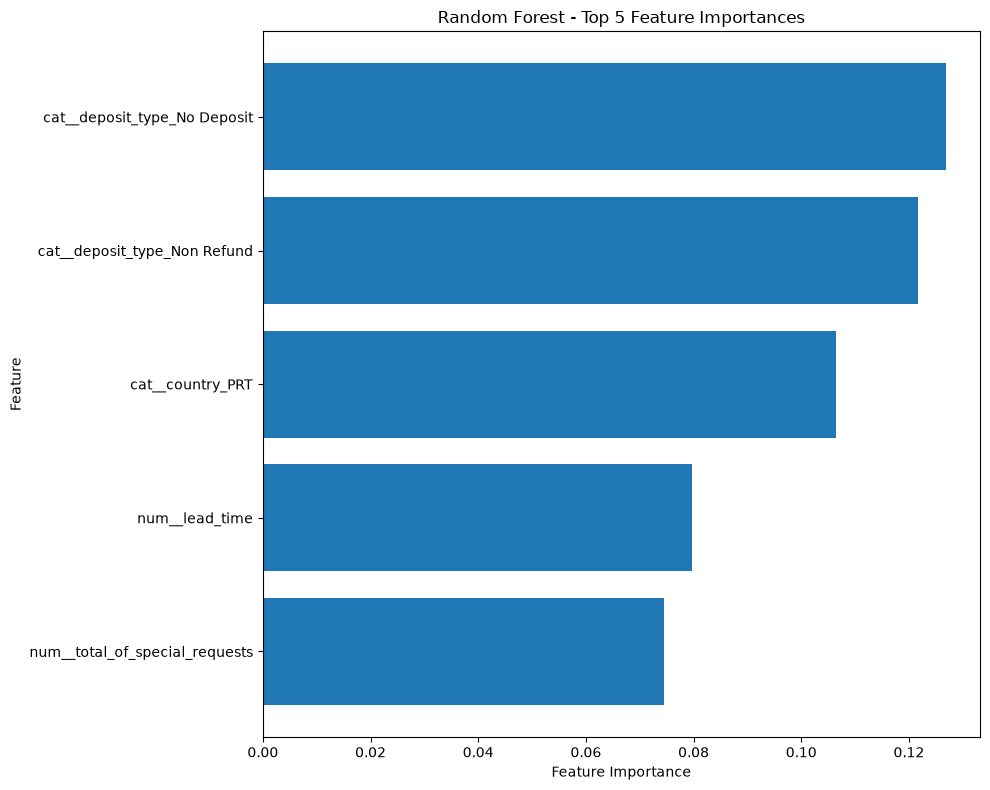

In [24]:
import matplotlib.pyplot as plt

# 중요도 상위 20개 특성 선택
top_n = 5
top_features = feature_importance.head(top_n).sort_values(
    "importance", ascending=True
)

plt.figure(figsize=(10, 8))
plt.barh(top_features["feature"], top_features["importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(f"Random Forest - Top {top_n} Feature Importances")
plt.tight_layout()
plt.show()

## 7. 결과 저장

In [25]:
OUTPUT_DIR = Path("rf_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

joblib.dump(rf_model, OUTPUT_DIR / "hotel_random_forest_model.joblib")

test_predictions = test[["source_row_id", "group_id", TARGET]].copy()
test_predictions["predicted_is_canceled"] = y_pred
test_predictions["cancel_probability"] = y_proba
test_predictions.to_csv(
    OUTPUT_DIR / "hotel_rf_test_predictions.csv",
    index=False, encoding="utf-8-sig"
)
feature_importance.to_csv(
    OUTPUT_DIR / "hotel_rf_feature_importance.csv",
    index=False, encoding="utf-8-sig"
)
tuning_results.to_csv(
    OUTPUT_DIR / "hotel_rf_tuning_results.csv",
    index=False, encoding="utf-8-sig"
)
pd.Series(results, name="score").to_csv(
    OUTPUT_DIR / "hotel_rf_metrics.csv",
    encoding="utf-8-sig"
)
print("저장 위치:", OUTPUT_DIR.resolve())

저장 위치: C:\Users\playdata2\work\팀프로젝트2\고도화\rf_outputs
